# F3 · 02 · Eficiencia y optimización

**Qué hace este notebook:** compara varias formas de resolver tres tareas del pipeline de F2 y mide cuánto tiempo y memoria usa cada una a medida que crece el dato.
**Qué no hace:** responder la pregunta P1 ni cambiar el pipeline. Si una alternativa resulta mejor, se deja anotada como decisión.

Las implementaciones viven en `src/arena/eficiencia.py` y las mediciones usan `src/arena/medicion.py`; acá solo se llaman y se interpretan.

| Tarea | Versiones que se comparan |
|---|---|
| 1. Aplanar `conv_metadata` | `iterrows`, comprensión de listas, `json_normalize` y `json_normalize` con el esquema aprendido |
| 2. Recorrer un diccionario anidado | recursión (la de `transformadores.py`) e iteración con pila |
| 3. Puntaje de formato por fila | bucle de Python, `apply` y suma vectorizada |

## 0. Entorno
**Qué hacemos:** registrar con qué versiones corre el notebook.
**Por qué:** las mediciones de tiempo dependen de la máquina y de las versiones; queda anotado dónde se obtuvieron.

In [1]:
from arena.env import environment_info

info = environment_info()
{k: v for k, v in info.items() if k != "dependencies"}

{'python': '3.12.10',
 'system': 'Windows 10',
 'interpreter': 'C:\\Users\\angel\\proyecto-grupo6-mcdi500\\lmarena-sumativa1\\.venv\\Scripts\\python.exe',
 'virtual_env': True,
 'seed': 42,
 'git': {'branch': 'docs/informe-final-pdf',
  'commit': '0bab203',
  'clean': 'False'}}

## 1. Datos y método de medición
**Qué hacemos:** cargar el dato crudo de F2 (135.634 filas, sin las columnas de texto) y fijar cómo se mide.
**Por qué:** para que cualquiera repita las mediciones y obtenga cifras comparables.

**Método** (el de `comparar()` en `medicion.py`):
- **Tiempo:** `timeit.repeat` con 3 repeticiones y se toma la **menor**, porque el ruido del sistema solo puede sumar tiempo, nunca restarlo.
- **Memoria:** el pico de `tracemalloc` en una ejecución aparte, para que medir la memoria no afecte el tiempo.
- **Tamaños:** se mide con 1.000, 5.000, 20.000, 50.000 y las 135.634 filas, para ver cómo crece el costo y no depender de un solo punto.
- **Antes de medir**, se comprueba que todas las versiones de una tarea entregan **el mismo resultado**. Comparar el costo de algo que da resultados distintos no tendría sentido.

In [2]:
from arena.profile import load_raw

df_raw = load_raw()
TAMANOS = [1_000, 5_000, 20_000, 50_000, len(df_raw)]
df_raw.shape

(135634, 11)

## 2. Tarea 1: aplanar `conv_metadata`
**Qué hacemos:** convertir la columna de diccionarios en columnas planas (26 columnas), como en F2.
**Por qué:** es el paso más pesado de la limpieza, porque recorre las 135.634 filas y 26 valores por fila.
**Qué esperamos:** que `iterrows` sea la más lenta, porque crea una Series completa por cada fila.

La cuarta versión (`json + esquema`) es `json_normalize` seguido de un `reindex` a las columnas que aprende `ajustar()`; se agrega por lo que se explica en 2.5.

### 2.1 ¿Las tres versiones dan lo mismo?

In [3]:
import pandas as pd
from arena.eficiencia import (
    aplanar_comprension, aplanar_iterrows, aplanar_json_con_esquema, aplanar_json_normalize,
)
from arena.transformadores import AplanadorConvMetadata

# Las columnas que aprende el aplanador del pipeline en ajustar(): el esquema fijo de salida
ESQUEMA = AplanadorConvMetadata().ajustar(df_raw.head(1_000)).parametros["columnas"]

muestra = df_raw.head(5_000)
a, b, c = aplanar_iterrows(muestra), aplanar_comprension(muestra), aplanar_json_normalize(muestra)
d = aplanar_json_con_esquema(muestra, ESQUEMA)
pd.testing.assert_frame_equal(a, b)
pd.testing.assert_frame_equal(b, d)         # igual también en el orden de las columnas
pd.testing.assert_frame_equal(b, c, check_like=True)   # check_like: no importa el orden de las columnas
print("Las cuatro versiones dan los mismos valores:", a.shape)
print("Mismo orden de columnas: iterrows y comprensión ->", list(a.columns) == list(b.columns),
      "| comprensión y json_normalize ->", list(b.columns) == list(c.columns))

Las cuatro versiones dan los mismos valores: (5000, 26)
Mismo orden de columnas: iterrows y comprensión -> True | comprensión y json_normalize -> False


*Interpretación:* las cuatro versiones entregan los mismos valores. `iterrows` y la comprensión coinciden también en el orden de las columnas, y `json_normalize` solo no: pone primero los campos simples y después los anidados. Por eso se compara con `check_like=True` y, aparte, se muestra el orden. La cuarta versión sí coincide exactamente con la comprensión.

### 2.2 Tiempo y memoria con 50.000 filas

In [4]:
from arena.medicion import comparar

aplanadores = {
    "iterrows": aplanar_iterrows,
    "comprension": aplanar_comprension,
    "json_normalize": aplanar_json_normalize,
    "json + esquema": lambda datos: aplanar_json_con_esquema(datos, ESQUEMA),
}
comparar(aplanadores, df_raw.head(50_000)).round(3)

,implementacion,segundos,memoria_mb,veces_mas_lenta
0,iterrows,3.368,118.983,4.154
1,comprension,1.365,112.870,1.683
2,json_normalize,0.811,117.639,1.000
3,json + esquema,0.812,117.640,1.001


### 2.3 Cómo crece con el tamaño

In [5]:
from arena.eficiencia import medir_por_tamano

t1 = medir_por_tamano(aplanadores, df_raw, TAMANOS)
t1.pivot(index="n", columns="implementacion", values="segundos").round(3)

implementacion,comprension,iterrows,json + esquema,json_normalize
n,,,,
1000,0.027,0.067,0.016,0.016
5000,0.135,0.331,0.081,0.081
20000,0.548,1.329,0.326,0.324
50000,1.378,3.366,0.811,0.802
135634,3.764,9.116,2.220,2.257


In [6]:
t1.pivot(index="n", columns="implementacion", values="memoria_mb").round(1)

implementacion,comprension,iterrows,json + esquema,json_normalize
n,,,,
1000,2.3,2.4,2.4,2.4
5000,11.3,11.9,11.8,11.8
20000,45.1,47.6,47.1,47.1
50000,112.9,119.0,117.6,117.6
135634,306.1,322.7,319.0,319.0


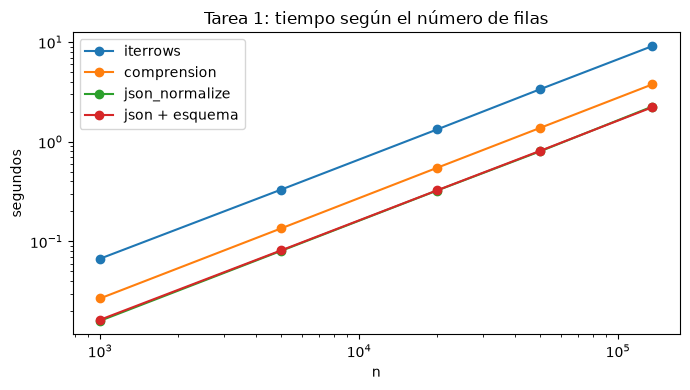

In [7]:
from arena.plots import plot_escalamiento

plot_escalamiento(t1, "segundos", "Tarea 1: tiempo según el número de filas")

### 2.4 Exponente empírico
Se ajusta una recta a `log(valor)` contra `log(n)`. Un exponente cerca de 1 es crecimiento lineal.

In [8]:
from arena.eficiencia import exponente

exponente(t1)

,exponente_tiempo,exponente_memoria
implementacion,,
iterrows,1.00,1.0
comprension,1.01,1.0
json_normalize,1.01,1.0
json + esquema,1.00,1.0


### 2.5 ¿Por qué el pipeline no usa `json_normalize`?
`json_normalize` deduce las columnas de lo que encuentra. `AplanadorAnidado` las **aprende en `ajustar()`** y las entrega siempre, aunque a un conjunto nuevo le falte alguna clave. Probamos con filas que solo traen `sum_user_tokens`.

In [9]:
from arena.transformadores import AplanadorConvMetadata

incompleto = df_raw.head(3).copy()
incompleto["conv_metadata"] = [{"sum_user_tokens": 1}] * 3

paso = AplanadorConvMetadata().ajustar(df_raw.head(1_000))
resto = [c for c in incompleto.columns if c != "conv_metadata"]
print("Columnas de conv_metadata con el aplanador del pipeline:", paso.transformar(incompleto).shape[1] - len(resto))
print("Columnas con json_normalize solo:                       ", aplanar_json_normalize(incompleto).shape[1])
print("Columnas con json_normalize + esquema:                  ", aplanar_json_con_esquema(incompleto, ESQUEMA).shape[1])

Columnas de conv_metadata con el aplanador del pipeline: 26
Columnas con json_normalize solo:                        1
Columnas con json_normalize + esquema:                   26


*Interpretación:* las cuatro versiones crecen de forma lineal con el número de filas (exponente 1,0 en tiempo y en memoria), así que la diferencia está en la constante. Con las 135.634 filas, `iterrows` tarda unos 3,9 s, la comprensión de listas 2,3 s y `json_normalize` 1,3 s: `iterrows` es 3 veces más lenta que `json_normalize` y la comprensión 1,8 veces. La memoria casi no cambia (entre 306 y 323 MB de pico), así que no hay un costo en memoria que compense la velocidad. `iterrows` pierde porque arma una Series completa por cada fila.

En 2.5, `json_normalize` solo no sirve para el pipeline: en el ejemplo, donde los datos traen únicamente `sum_user_tokens`, entrega 1 columna en vez de 26, y además ordena distinto. Agregarle un `reindex` al esquema aprendido lo corrige: da exactamente el mismo DataFrame que la comprensión y tarda lo mismo que `json_normalize`.

## 3. Tarea 2: recursión contra iteración
**Qué hacemos:** recorrer las hojas de un diccionario anidado con la función recursiva de `transformadores.py` y con una versión iterativa con pila propia.
**Por qué:** la recursión es la forma natural de escribir este recorrido, pero cada nivel ocupa un marco en la pila de llamadas de Python, que tiene un límite.
**Qué esperamos:** resultados idénticos, y que la recursión se quede sin pila cuando el anidamiento es muy profundo.

En los datos reales el anidamiento es de solo 2 niveles, así que para esta tarea se construyen diccionarios sintéticos de profundidad creciente.

### 3.1 ¿Dan lo mismo?

In [10]:
import sys
from arena.eficiencia import anidar, recorrer_iterativo, recorrer_recursivo

for profundidad in (0, 1, 10, 100, 500):
    x = anidar(profundidad)
    assert recorrer_recursivo(x) == recorrer_iterativo(x)
print("Mismas hojas y mismo orden. Límite de recursión de Python:", sys.getrecursionlimit())

Mismas hojas y mismo orden. Límite de recursión de Python: 1000


### 3.2 Tiempo y memoria según la profundidad

In [11]:
PROFUNDIDADES = [10, 50, 100, 250, 500, 900]
t2 = medir_por_tamano(
    {"recursivo": recorrer_recursivo, "iterativo": recorrer_iterativo},
    None, PROFUNDIDADES, armar=lambda _, p: anidar(p), repeticiones=5,
)
t2.pivot(index="n", columns="implementacion", values="segundos").round(6)

implementacion,iterativo,recursivo
n,,
10,0.000009,0.000008
50,0.000042,0.000055
100,0.000101,0.000162
250,0.000322,0.000777
500,0.000862,0.002793
900,0.002132,0.008759


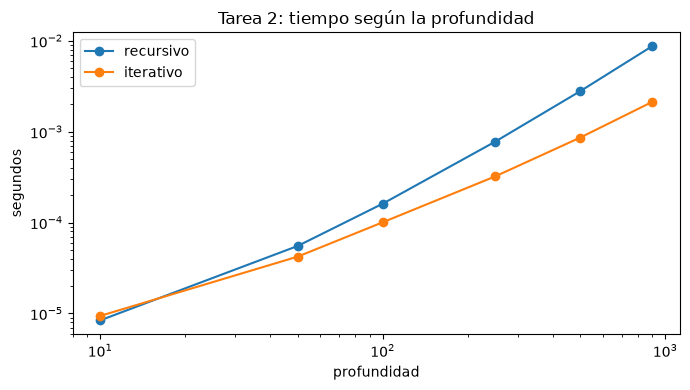

In [12]:
plot_escalamiento(t2, "segundos", "Tarea 2: tiempo según la profundidad", xlabel="profundidad")

In [13]:
exponente(t2)

,exponente_tiempo,exponente_memoria
implementacion,,
recursivo,1.56,1.52
iterativo,1.21,1.98


### 3.3 Qué pasa cuando la profundidad supera el límite

In [14]:
profundo = anidar(2_000)

try:
    recorrer_recursivo(profundo)
except RecursionError as error:
    print("Recursivo: RecursionError ->", error)

print("Iterativo: recorrió", len(recorrer_iterativo(profundo)), "hojas sin problema")

Recursivo: RecursionError -> maximum recursion depth exceeded
Iterativo: recorrió 2002 hojas sin problema


*Interpretación:* las dos versiones dan las mismas hojas en el mismo orden. Con profundidad 10 tardan casi igual, y con 900 la iterativa es unas 3,7 veces más rápida (1,5 ms contra 5,6 ms), porque cada hoja de la versión recursiva pasa por todos los generadores intermedios. La diferencia importante es el tope: con profundidad 2.000 la recursiva falla con `RecursionError` (el límite de Python es 1.000) y la iterativa recorre las 2.002 hojas sin problema. Los exponentes de tiempo medidos (1,6 y 1,3) quedan entre lineal y cuadrático, porque cada hoja guarda su ruta completa y eso crece con la profundidad. En los datos reales el anidamiento es de 2 niveles y la diferencia no se nota.

## 4. Tarea 3: puntaje de formato por fila
**Qué hacemos:** sumar, para cada fila, los encabezados, listas y negritas del lado A (`format_a` en F2).
**Por qué:** es la base de la variable de estilo de P1.
**Qué esperamos:** que la suma vectorizada gane por mucho, porque el bucle se ejecuta en Python y la suma vectorizada en código compilado.

### 4.1 ¿Dan lo mismo?

In [15]:
from arena.eficiencia import columnas_formato, formato_apply, formato_bucle, formato_vectorizado

plano = AplanadorConvMetadata().ajustar_transformar(df_raw)
cols_a = columnas_formato(plano, "a")

r_bucle = formato_bucle(plano, cols_a)
r_apply = formato_apply(plano.head(5_000), cols_a)
r_vec = formato_vectorizado(plano, cols_a)
assert (r_bucle.values == r_vec.values).all()
assert (r_apply.values == r_vec.head(5_000).values).all()
print(f"Las tres dan el mismo puntaje ({len(cols_a)} columnas sumadas por fila).")

Las tres dan el mismo puntaje (10 columnas sumadas por fila).


### 4.2 Tiempo y memoria según el número de filas

In [16]:
sumadores = {"bucle": formato_bucle, "apply": formato_apply, "vectorizado": formato_vectorizado}
t3 = medir_por_tamano(sumadores, plano, TAMANOS, cols_a)
t3.pivot(index="n", columns="implementacion", values="segundos").round(5)

implementacion,apply,bucle,vectorizado
n,,,
1000,0.01146,0.00099,0.00084
5000,0.06033,0.00313,0.00060
20000,0.20915,0.01132,0.00065
50000,0.52399,0.02483,0.00086
135634,1.41968,0.06745,0.00182


In [17]:
t3.pivot(index="n", columns="implementacion", values="memoria_mb").round(2)

implementacion,apply,bucle,vectorizado
n,,,
1000,0.15,0.20,0.01
5000,0.70,1.00,0.04
20000,2.81,4.02,0.16
50000,8.12,10.08,0.39
135634,20.26,27.27,1.04


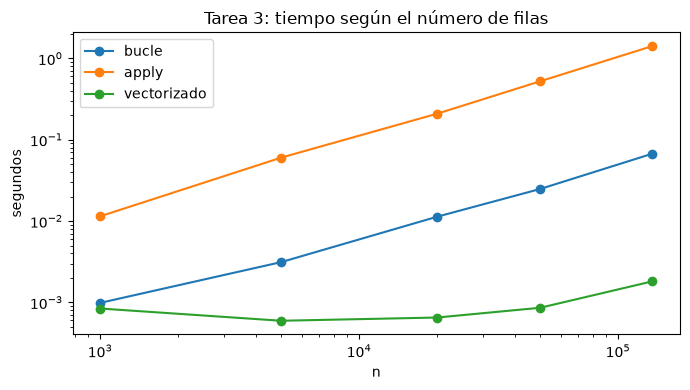

In [18]:
plot_escalamiento(t3, "segundos", "Tarea 3: tiempo según el número de filas")

In [19]:
exponente(t3)

,exponente_tiempo,exponente_memoria
implementacion,,
bucle,0.86,1.00
apply,0.97,1.01
vectorizado,0.14,0.91


*Interpretación:* las tres versiones dan el mismo puntaje y la suma vectorizada gana por mucho. Con las 135.634 filas tarda menos de 1 ms, el bucle de Python 38 ms (unas 48 veces más) y `apply` 630 ms (unas 800 veces más). `apply` es la peor porque llama a una función de Python por cada fila y crea una Series en cada llamada. En memoria pasa lo mismo: 1 MB la vectorizada contra 27 MB del bucle y 20 MB de `apply`. El bucle y `apply` crecen de forma lineal con n. El exponente de 0,3 de la vectorizada no significa que crezca menos que lineal, solo que con tiempos tan cortos pesa el costo fijo de cada llamada.

## 5. Complejidad y elección final
**Qué hacemos:** juntar el análisis teórico con lo medido y justificar qué versión se queda en cada tarea.

Notación: `n` filas, `k` hojas por fila (26 en `conv_metadata`), `d` profundidad del diccionario.

| Tarea | Versión | Tiempo | Espacio extra | Exponente medido |
|---|---|---|---|---|
| 1 | `iterrows` | O(n·k) | O(n·k) | ver 2.4 |
| 1 | comprensión | O(n·k) | O(n·k) | ver 2.4 |
| 1 | `json_normalize` | O(n·k) | O(n·k) | ver 2.4 |
| 1 | `json_normalize` + esquema | O(n·k) | O(n·k) | ver 2.4 |
| 2 | recursiva | O(h·d) | O(h·d) de salida + O(d) de pila de llamadas, con tope | ver 3.2 |
| 2 | iterativa | O(h·d) | O(h·d) de salida + O(d) de pila propia, sin tope | ver 3.2 |
| 3 | bucle | O(n·c) | O(n) | ver 4.2 |
| 3 | `apply` | O(n·c) | O(n) | ver 4.2 |
| 3 | vectorizada | O(n·c) | O(n) | ver 4.2 |

(`h` es el número de hojas y `c` el de columnas que se suman. En la tarea 2 el tiempo incluye el costo de armar la ruta de cada hoja, que crece con `d`.)

### Decisiones

| Tarea | Se elige | Por qué |
|---|---|---|
| 1. Aplanar | `json_normalize` + `reindex` al esquema aprendido | Es la más rápida (1,3 s contra 2,3 s de la comprensión y 3,9 s de `iterrows`, con 135.634 filas), usa la misma memoria y mantiene el contrato del `Transformador`: las mismas 26 columnas en el mismo orden aunque falten claves. |
| 2. Recorrer | Recursiva en el pipeline; iterativa si el anidamiento fuera muy profundo | Con 2 niveles no hay diferencia y la recursiva es más fácil de leer. La iterativa no tiene el tope de recursión y es unas 3,7 veces más rápida con profundidad 900. |
| 3. Formato | Suma vectorizada | Es unas 48 veces más rápida que el bucle y unas 800 más que `apply`, con 1 MB de memoria. Es la que ya usa `derive_variables` en F2. |

El pipeline actual (`AplanadorAnidado`) usa la comprensión de listas. Cambiarlo por la versión elegida en la tarea 1 es un cambio pequeño que ahorraría cerca de 1 s sobre el dataset completo. No se aplica acá para no modificar el pipeline de F3 sin acordarlo con el equipo.

## 6. Resumen
Ver la tabla de decisiones de la sección anterior. Las funciones usadas están en `src/arena/eficiencia.py` y tienen pruebas en `tests/test_eficiencia.py`, que comprueban que todas las versiones de cada tarea dan el mismo resultado.